In [1]:
import pandas as pd

In [2]:
df = pd.read_csv('../01_python/data/sales.csv')

In [3]:
df

,date,product,category,quantity,unit_price
0,2026-01-05,Laptop,Electronics,2,750.00
1,2026-01-07,Mouse,Electronics,10,15.50
2,2026-01-12,Desk Chair,Furniture,3,120.00
3,2026-02-02,Notebook,Stationery,50,2.25
4,2026-02-14,Monitor,Electronics,4,210.00
5,2026-02-20,Bookshelf,Furniture,1,95.00
6,2026-03-03,Pen Pack,Stationery,30,4.80
7,2026-03-09,Keyboard,Electronics,6,45.00
8,2026-03-15,Desk Lamp,Furniture,five,30.00
9,2026-03-21,Stapler,NaN,8,7.50


In [4]:
df["quantity"]

0        2
1       10
2        3
3       50
4        4
5        1
6       30
7        6
8     five
9        8
10       5
11       2
Name: quantity, dtype: str

In [5]:
df.head()

,date,product,category,quantity,unit_price
0,2026-01-05,Laptop,Electronics,2,750.00
1,2026-01-07,Mouse,Electronics,10,15.50
2,2026-01-12,Desk Chair,Furniture,3,120.00
3,2026-02-02,Notebook,Stationery,50,2.25
4,2026-02-14,Monitor,Electronics,4,210.00


In [6]:
df.shape

(12, 5)

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 12 entries, 0 to 11
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   date        12 non-null     str    
 1   product     12 non-null     str    
 2   category    11 non-null     str    
 3   quantity    12 non-null     str    
 4   unit_price  12 non-null     float64
dtypes: float64(1), str(4)
memory usage: 612.0 bytes


In [8]:
df.isna()

,date,product,category,quantity,unit_price
0,False,False,False,False,False
1,False,False,False,False,False
2,False,False,False,False,False
3,False,False,False,False,False
4,False,False,False,False,False
5,False,False,False,False,False
6,False,False,False,False,False
7,False,False,False,False,False
8,False,False,False,False,False
9,False,False,True,False,False


In [9]:
df.isna().sum()

date          0
product       0
category      1
quantity      0
unit_price    0
dtype: int64

In [10]:
df.describe()

,unit_price
count,12.000000
mean,126.670833
std,208.180124
min,2.250000
25%,13.500000
50%,52.500000
75%,135.000000
max,750.000000


## Exercise 1 answers
1. **12 rows, 5 columns** (`df.shape` → `(12, 5)`).
2. `quantity` is `str` because row 8 (Desk Lamp) contains the text `"five"`.
   A column can only have one type, so pandas stored the whole column as text.
   Even `"2"` is text now, so you can't do maths with it until it's converted.
3. `category` has 1 missing value (row 9, Stapler). pandas put `NaN` there,
   its marker for a missing value (like `null` in PHP).


## Exercise 2: Clean the data

In [11]:
df["quantity"] = pd.to_numeric(df["quantity"], errors='coerce')
df["quantity"]

0      2.0
1     10.0
2      3.0
3     50.0
4      4.0
5      1.0
6     30.0
7      6.0
8      NaN
9      8.0
10     5.0
11     2.0
Name: quantity, dtype: float64

In [12]:
df["category"]

0     Electronics
1     Electronics
2       Furniture
3      Stationery
4     Electronics
5       Furniture
6      Stationery
7     Electronics
8       Furniture
9             NaN
10    Electronics
11      Furniture
Name: category, dtype: str

In [13]:
df["category"] = df["category"].str.strip().replace('', None)

In [14]:
df["category"]

0     Electronics
1     Electronics
2       Furniture
3      Stationery
4     Electronics
5       Furniture
6      Stationery
7     Electronics
8       Furniture
9             NaN
10    Electronics
11      Furniture
Name: category, dtype: str

In [15]:
bad_mask = df["quantity"].isna() | df["category"].isna()
bad_mask


0     False
1     False
2     False
3     False
4     False
5     False
6     False
7     False
8      True
9      True
10    False
11    False
dtype: bool

In [16]:
df[bad_mask].index + 2

RangeIndex(start=10, stop=12, step=1)

In [17]:
df[bad_mask]


,date,product,category,quantity,unit_price
8,2026-03-15,Desk Lamp,Furniture,NaN,30.0
9,2026-03-21,Stapler,NaN,8.0,7.5


In [18]:
df[(df["quantity"] > 5) & (df["category"] == "Furniture")]


,date,product,category,quantity,unit_price


In [19]:
df = df.dropna(subset=["quantity", "category"])
df.shape


(10, 5)

In [20]:
df = df.reset_index(drop=True)    # drop=True: don't keep the old index as a column


In [21]:
df["quantity"] = df["quantity"].astype(int)


In [22]:
df["date"] = pd.to_datetime(df["date"])
df["date"].dt.day_name().head(3)


0       Monday
1    Wednesday
2       Monday
Name: date, dtype: str

In [23]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   date        10 non-null     datetime64[us]
 1   product     10 non-null     str           
 2   category    10 non-null     str           
 3   quantity    10 non-null     int64         
 4   unit_price  10 non-null     float64       
dtypes: datetime64[us](1), float64(1), int64(1), str(2)
memory usage: 532.0 bytes


## Exercise 2 answers
- `errors="coerce"` turned `"five"` into `NaN` (missing).
- Bad rows: index 8 (Desk Lamp, bad quantity) and 9 (Stapler, no category).
  These are CSV lines 10 and 11: +1 because the index starts at 0, and +1 for the header line.
- After `to_numeric`, `quantity` was `float64` because `NaN` is a float.
  I could only convert it to `int` *after* dropping the NaN rows.
- 10 rows remain. `quantity` is `int64`, and `date` is `datetime64[us]`.
- `read_csv` doesn't trim whitespace, so I still need `.str.strip()`, as in Task 2.


## Exercise 3:  The Report


In [24]:
df["total"] = df["quantity"] * df["unit_price"]
df.head()

,date,product,category,quantity,unit_price,total
0,2026-01-05,Laptop,Electronics,2,750.00,1500.0
1,2026-01-07,Mouse,Electronics,10,15.50,155.0
2,2026-01-12,Desk Chair,Furniture,3,120.00,360.0
3,2026-02-02,Notebook,Stationery,50,2.25,112.5
4,2026-02-14,Monitor,Electronics,4,210.00,840.0


In [26]:
df["month"] = df["date"].dt.strftime("%Y-%m")
df[["date", "month"]].head(3)

,date,month
0,2026-01-05,2026-01
1,2026-01-07,2026-01
2,2026-01-12,2026-01


In [27]:
df["total"].sum()

np.float64(4136.5)

In [28]:
df.groupby("category")["total"].sum()

category
Electronics    3065.0
Furniture       815.0
Stationery      256.5
Name: total, dtype: float64

In [29]:
df.groupby("month")["total"].sum()

month
2026-01    2015.0
2026-02    1047.5
2026-03     414.0
2026-04     660.0
Name: total, dtype: float64

In [30]:
df.nlargest(3, "total")[["product","total"]]

,product,total
0,Laptop,1500.0
4,Monitor,840.0
2,Desk Chair,360.0


In [31]:
df[df["category"] == "Electronics"]

,date,product,category,quantity,unit_price,total,month
0,2026-01-05,Laptop,Electronics,2,750.0,1500.0,2026-01
1,2026-01-07,Mouse,Electronics,10,15.5,155.0,2026-01
4,2026-02-14,Monitor,Electronics,4,210.0,840.0,2026-02
7,2026-03-09,Keyboard,Electronics,6,45.0,270.0,2026-03
8,2026-04-01,Webcam,Electronics,5,60.0,300.0,2026-04


In [32]:
df.groupby("category")["total"].agg(["sum", "count", "mean"])


,sum,count,mean
category,,,
Electronics,3065.0,5,613.000000
Furniture,815.0,3,271.666667
Stationery,256.5,2,128.250000


In [33]:
df.sort_values("total", ascending=False).head(3)


,date,product,category,quantity,unit_price,total,month
0,2026-01-05,Laptop,Electronics,2,750.0,1500.0,2026-01
4,2026-02-14,Monitor,Electronics,4,210.0,840.0,2026-02
9,2026-04-11,Filing Cabinet,Furniture,2,180.0,360.0,2026-04


## Exercise 3 answers

| Task 2 function | pandas |
|---|---|
| `grand_total(sales)` | `df["total"].sum()` |
| `total_by_category(sales)` | `df.groupby("category")["total"].sum()` |
| `total_by_month(sales)` | `df.groupby("month")["total"].sum()` |
| `top_n(sales, 3)` | `df.nlargest(3, "total")` |
| `filter_category(sales, "Electronics")` | `df[df["category"] == "Electronics"]` |

All numbers match Task 2: 4136.5 in total; 3065.0 / 815.0 / 256.5 by category;
2015.0 / 1047.5 / 414.0 / 660.0 by month; 5 Electronics rows.
No loops: pandas works on whole columns at once.


## Exercise: Charts

In [34]:
import matplotlib.pyplot as plt
from pathlib import Path

plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

output_dir = Path("output")
output_dir.mkdir(exist_ok=True)

by_category = df.groupby("category")["total"].sum()
by_month = df.groupby("month")["total"].sum()


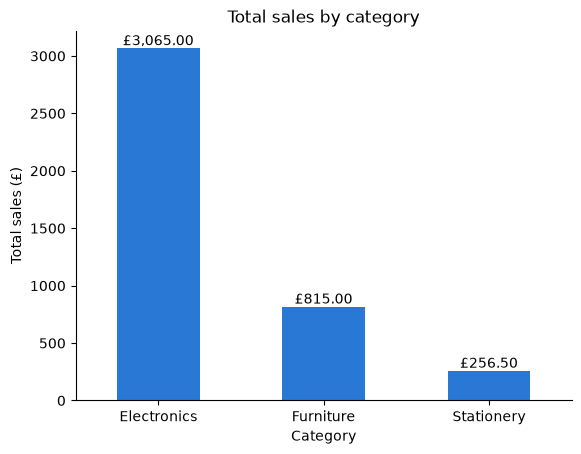

In [35]:
ax = by_category.plot(kind="bar", color="#2a78d6", rot=0)
ax.bar_label(ax.containers[0], fmt="£{:,.2f}")
plt.title("Total sales by category")
plt.xlabel("Category")
plt.ylabel("Total sales (£)")
plt.savefig(output_dir / "sales_by_category.png", bbox_inches="tight")
plt.show()


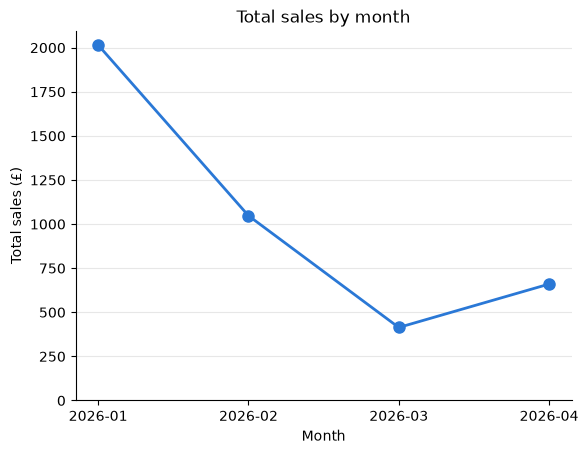

In [38]:
ax = by_month.plot(kind="line", marker="o", color="#2a78d6",
                   linewidth=2, markersize=8, xticks=range(len(by_month)))
ax.set_ylim(bottom=0)
ax.grid(axis="y", alpha=0.3)
plt.title("Total sales by month")
plt.xlabel("Month")
plt.ylabel("Total sales (£)")
plt.savefig(output_dir / "sales_by_month.png", bbox_inches="tight")
plt.show()


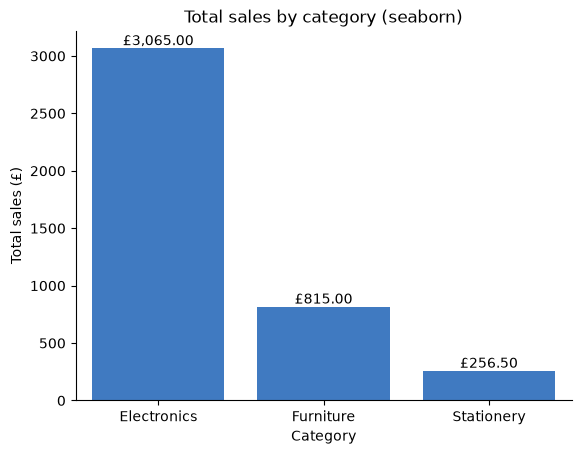

In [41]:
import seaborn as sns

ax = sns.barplot(data=df, x="category", y="total",
                 estimator="sum", errorbar=None, color="#2a78d6")
ax.bar_label(ax.containers[0], fmt="£{:,.2f}")
plt.title("Total sales by category (seaborn)")
plt.xlabel("Category")
plt.ylabel("Total sales (£)")
plt.show()


## Exercise 4 answers
- Bar chart for categories (separate things); line chart for months (change over time).
- `savefig` must come **before** `show`, or the saved PNG is blank.
- `set_ylim(bottom=0)` keeps the scale honest.
- seaborn groups the raw data itself, but its default is the **mean**, so I needed `estimator="sum"`.
- I prefer ___ because ___.
